# Verifica del residuo di Black-Scholes

**Scopo**: verificare numericamente che la formula chiusa di Black-Scholes
soddisfa il residuo `R[Ṽ] ≡ 0` in tempo residuo τ = T - t, dove:

R[Ṽ](τ, S) = ∂Ṽ/∂τ - ½σ²S² ∂²Ṽ/∂S² - rS ∂Ṽ/∂S + rṼ

**Due metodi**:
1. **Differenze finite** (numpy): il residuo → 0 con ordine O(h²).
2. **Autodiff** (PyTorch): il residuo è ≈ 0 a precisione macchina.

**Perché è importante**: la PINN (M5) minimizzerà ||R[V_θ]||², dove V_θ è
la rete. Prima di addestrare la rete, dobbiamo sapere che il residuo
"vero" (quello della formula chiusa) è zero numerico. Altrimenti
staremmo facendo convergere la rete a un residuo non nullo.

In [ ]:
#pip install numpy scipy torch matplotlib
import numpy as np
import torch
from scipy.stats import norm
import matplotlib.pyplot as plt
from pathlib import Path


S0, K, T, r, sigma = 100.0, 100.0, 1.0, 0.05, 0.2

RESULTS = Path("../../results")
RESULTS.mkdir(exist_ok=True)

print(f"Parametri: S0={S0}, K={K}, T={T}, r={r}, sigma={sigma}")
print(f"Torch version: {torch.__version__}")

Parametri: S0=100.0, K=100.0, T=1.0, r=0.05, sigma=0.2
Torch version: 2.11.0+cpu


## 1. Formula chiusa (oracolo)

Implementiamo la call europea di Black-Scholes. Attenzione al cambio di
variabile: lavoriamo in **tempo residuo** τ = T - t, quindi

Ṽ(τ, S) = C_BS(S, K, T - τ, r, σ)

dove C_BS è la formula chiusa standard in tempo fisico t.

In [ ]:
def bs_call_np(S, K, T, r, sigma):
    """Call europea Black-Scholes in tempo fisico T (time-to-maturity)."""
    T = np.asarray(T, dtype=float)
    tiny = T < 1e-12
    T_safe = np.where(tiny, 1.0, T)  
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T_safe) / (sigma * np.sqrt(T_safe))
    d2 = d1 - sigma * np.sqrt(T_safe)
    price = S * norm.cdf(d1) - K * np.exp(-r * T_safe) * norm.cdf(d2)
    return np.where(tiny, np.maximum(S - K, 0.0), price)


def V_tilde_np(tau, S, K, T, r, sigma):
    """Ṽ(τ, S) = C_BS(S, K, T - τ, r, σ)."""
    return bs_call_np(S, K, tau, r, sigma)


V_at_tau_T = V_tilde_np(T, S0, K, T, r, sigma)
V_standard = bs_call_np(S0, K, T, r, sigma)
print(f"Ṽ(τ=T, S=100) = {V_at_tau_T:.10f}")
print(f"C_BS(S=100)   = {V_standard:.10f}")
print(f"differenza    = {abs(V_at_tau_T - V_standard):.2e}")


V_at_tau_0 = V_tilde_np(0.0, np.array([80.0, 100.0, 120.0]), K, T, r, sigma)
print(f"\nṼ(τ=0, S=[80,100,120]) = {V_at_tau_0}")
print(f"Payoff atteso           = [0, 0, 20]")

Ṽ(τ=T, S=100) = 10.4505835722
C_BS(S=100)   = 10.4505835722
differenza    = 0.00e+00

Ṽ(τ=0, S=[80,100,120]) = [ 0.  0. 20.]
Payoff atteso           = [0, 0, 20]


## 2. Residuo via differenze finite (numpy)

Calcoliamo il residuo R[Ṽ] su un punto **interno** del dominio, ad esempio
τ = T/2, S = K. Perché interno?

- A τ = 0 il payoff ha un kink in S = K (derivata seconda discontinua).
- A τ = T il prezzo è smooth, ma vogliamo testare punti generici.

Su un punto smooth, le differenze centrali hanno errore di troncamento
O(h²), quindi R_FD → 0 con ordine 2 al raffinarsi della griglia.

In [ ]:
def residual_fd(tau, S, K, T, r, sigma, h_tau, h_S):
    """Residuo R[Ṽ] via differenze centrali in (τ, S)."""
    # ∂Ṽ/∂τ 
    V_tau_plus  = V_tilde_np(tau + h_tau, S, K, T, r, sigma)
    V_tau_minus = V_tilde_np(tau - h_tau, S, K, T, r, sigma)
    dV_dtau = (V_tau_plus - V_tau_minus) / (2 * h_tau)

    # ∂Ṽ/∂S
    V_S_plus  = V_tilde_np(tau, S + h_S, K, T, r, sigma)
    V_S_minus = V_tilde_np(tau, S - h_S, K, T, r, sigma)
    dV_dS = (V_S_plus - V_S_minus) / (2 * h_S)

    # ∂²Ṽ/∂S² 
    V_SS = (V_S_plus - 2 * V_tilde_np(tau, S, K, T, r, sigma) + V_S_minus) / h_S**2

    # Residual
    V = V_tilde_np(tau, S, K, T, r, sigma)
    return dV_dtau - 0.5 * sigma**2 * S**2 * V_SS - r * S * dV_dS + r * V



tau_test = T / 2
S_test = K
h = 1e-3
res = residual_fd(tau_test, S_test, K, T, r, sigma, h, h)
print(f"R[Ṽ](τ={tau_test}, S={S_test}) con h={h}: {res:.6e}")
print("(deve essere piccolo, ~O(h²) = {:.1e})".format(h**2))

R[Ṽ](τ=0.5, S=100.0) con h=0.001: 5.502320e-06
(deve essere piccolo, ~O(h²) = 1.0e-06)


## 3. Studio di convergenza

Raffiniamo h e verifichiamo che il residuo decresce come O(h²).
Se non lo fa, c'è un bug nella formula o nella definizione del residuo.

In [ ]:

hs = np.array([1e-1, 5e-2, 2e-2, 1e-2, 5e-3, 2e-3, 1e-3, 5e-4, 2e-4, 1e-4])
residuals = []
for h in hs:
    r_val = residual_fd(tau_test, S_test, K, T, r, sigma, h, h)
    residuals.append(abs(r_val))

residuals = np.array(residuals)


mask = (hs <= 5e-2) & (hs >= 2e-3)
coeffs = np.polyfit(np.log(hs[mask]), np.log(residuals[mask]), 1)
order_est = coeffs[0]

print(f"{'h':>10} {'|R|':>14} {'ratio':>10}")
print("-" * 36)
for i, h in enumerate(hs):
    ratio = residuals[i-1] / residuals[i] if i > 0 else np.nan
    print(f"{h:>10.1e} {residuals[i]:>14.4e} {ratio:>10.2f}")
print(f"\nOrdine stimato: {order_est:.2f} (atteso: ~2 per differenze centrali)")

         h            |R|      ratio
------------------------------------
   1.0e-01     2.8670e-02        nan
   5.0e-02     7.0723e-03       4.05
   2.0e-02     1.1274e-03       6.27
   1.0e-02     2.8169e-04       4.00
   5.0e-03     7.0444e-05       4.00
   2.0e-03     1.2170e-05       5.79
   1.0e-03     5.5023e-06       2.21
   5.0e-04     7.6546e-06       0.72
   2.0e-04     5.5380e-05       0.14
   1.0e-04     1.5758e-05       3.51

Ordine stimato: 1.98 (atteso: ~2 per differenze centrali)


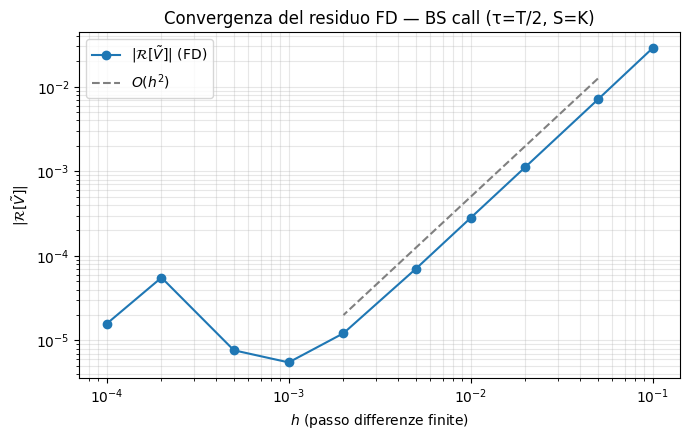

In [ ]:

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(hs, residuals, 'o-', label=r'$|\mathcal{R}[\tilde V]|$ (FD)', lw=1.5)
# O(h²)
h_ref = hs[mask]
ax.loglog(h_ref, 5.0 * h_ref**2, '--', label=r'$O(h^2)$', color='gray')

ax.set_xlabel(r'$h$ (passo differenze finite)')
ax.set_ylabel(r'$|\mathcal{R}[\tilde V]|$')
ax.set_title('Convergenza del residuo FD — BS call (τ=T/2, S=K)')
ax.legend()
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS / "m1_residual_fd_convergence.png", dpi=150)
plt.show()

## 4. Residuo via autodiff (PyTorch)

Lo stesso residuo, ma calcolato con autodiff invece di differenze finite.
Qui il residuo dovrebbe essere **≈ 0 a precisione macchina** (float64),
perché la formula chiusa soddisfa la PDE esattamente.

È il "riscaldamento" per M5: useremo esattamente lo stesso meccanismo
(`torch.autograd.grad` con `create_graph=True`) per derivare la rete.

In [ ]:
def bs_call_torch(S, K, T, r, sigma):
    """Call europea Black-Scholes in PyTorch (differenziabile)."""
    d1 = (torch.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * torch.sqrt(T))
    d2 = d1 - sigma * torch.sqrt(T)
    return S * torch.special.ndtr(d1) - K * torch.exp(-r * T) * torch.special.ndtr(d2)


def residual_ad(tau, S, K, T, r, sigma):
    """Residuo R[Ṽ] via autodiff."""
    tau = tau.clone().requires_grad_(True)
    S = S.clone().requires_grad_(True)

    # Ṽ(τ, S) = C_BS(S, K, τ, r, σ)
    V = bs_call_torch(S, K, tau, r, sigma)

    dV_dtau = torch.autograd.grad(V, tau, torch.ones_like(V), create_graph=True)[0]
    dV_dS   = torch.autograd.grad(V, S,   torch.ones_like(V), create_graph=True)[0]
    d2V_dS2 = torch.autograd.grad(dV_dS, S, torch.ones_like(dV_dS), create_graph=True)[0]

    return dV_dtau - 0.5 * sigma**2 * S**2 * d2V_dS2 - r * S * dV_dS + r * V


# Test
tau_t = torch.tensor(tau_test, dtype=torch.float64)
S_t   = torch.tensor(S_test,   dtype=torch.float64)
res_ad = residual_ad(tau_t, S_t, K, T, r, sigma).item()
res_fd_fine = residual_fd(tau_test, S_test, K, T, r, sigma, 1e-4, 1e-4)

print(f"Residuo autodiff:       {res_ad:.4e}")
print(f"Residuo FD (h=1e-4):    {res_fd_fine:.4e}")
print(f"Rapporto |FD|/|AD|:     {abs(res_fd_fine)/max(abs(res_ad), 1e-16):.2e}")
print("\nAutodiff → precisione macchina (differenze centrali hanno errore O(h²)).")

Residuo autodiff:       7.2164e-16
Residuo FD (h=1e-4):    -1.5758e-05
Rapporto |FD|/|AD|:     2.18e+10

Autodiff → precisione macchina (differenze centrali hanno errore O(h²)).


## 5. Verifica su griglia (τ, S)

Per convincerci che il residuo AD è zero *ovunque* (non solo al punto di
test), campioniamo una griglia interna e riportiamo il massimo.

In [ ]:
tau_grid = torch.linspace(0.05, 0.95, 50, dtype=torch.float64)  
S_grid   = torch.linspace(70.0, 130.0, 50, dtype=torch.float64)

max_res = 0.0
for tau_i in tau_grid:
    for S_i in S_grid:
        rr = residual_ad(tau_i, S_i, K, T, r, sigma).item()
        max_res = max(max_res, abs(rr))

print(f"Max |R[Ṽ]| sulla griglia interna (50×50): {max_res:.4e}")
print("(atteso: ~1e-12, cioè a precisione macchina)")

Max |R[Ṽ]| sulla griglia interna (50×50): 6.3782e-14
(atteso: ~1e-12, cioè a precisione macchina)
